# Urban Flood Mapping with Sentinel-1: Hurricane Harvey in Houston (August 2017)

Hurricane Harvey stalled over southeast Texas at the end of August 2017 and dropped record-breaking rain on the
Houston area, flooding large parts of the city. In this notebook I map the flooding in Harris County with
Sentinel-1 radar, building on my original Earth Engine flood script.

Cities make radar flood mapping harder than open countryside:

- **Open ground and fields:** floodwater is smooth and reflects the radar away, so these areas turn **darker**
  (this is what my original script looked for).
- **Built-up areas:** water between buildings bounces the radar back off the walls ("double bounce"), so flooded
  neighbourhoods can turn **brighter** instead.

So I map both signals separately, leave out permanent water and higher ground, and then:

- compare my map with the **Global Flood Database** (MODIS) extent for Harvey,
- break the flooded area down by **land cover**, and estimate the **population** living in flooded areas,
- show the **rainfall** that caused it (GPM IMERG, as in my original script).

> Based on my original Earth Engine JavaScript flood-mapping script.

## 1. Setup

Slow Earth Engine results (statistics and map images) are saved to `outputs/houston_flood/` as they are computed,
so **Restart & Run All** after a restart is quick.

In [4]:
import os, io, json
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap, Normalize
import requests
from PIL import Image


In [5]:
import ee
ee.Authenticate(auth_mode="localhost")
ee.Initialize(project="add your GEE username here!")

## 2. Study area, dates and settings

In [6]:
# Folders where I save tables, map images and figures
FIG_DIR, OUT_DIR = "figures/houston_flood", "outputs/houston_flood"
MAP_DIR = f"{OUT_DIR}/map_images"
for d in (FIG_DIR, OUT_DIR, MAP_DIR):
    os.makedirs(d, exist_ok=True)

# Study area: Harris County, Texas (Houston). Change the county/state code to map somewhere else.
STATE_FP, COUNTY = "48", "Harris"       # 48 = Texas
roi = (ee.FeatureCollection("TIGER/2018/Counties")
         .filter(ee.Filter.eq("STATEFP", STATE_FP)).filter(ee.Filter.eq("NAME", COUNTY))
         .geometry())
ROI_NAME = "Harris County (Houston), Texas"
EVENT_NAME = "Hurricane Harvey"

# Radar before the storm vs. radar during the peak flooding
SAR_BEFORE = ("2017-08-01", "2017-08-25")
SAR_AFTER  = ("2017-08-27", "2017-09-03")
RAIN_WINDOW = ("2017-08-20", "2017-09-05")

SMOOTH_M    = 60     # radar speckle smoothing (focal mean, metres), as in my original script
CHANGE_DB   = 3.0    # radar change (dB) counted as real change; my original script used 5 dB
WATER_DB    = -15.0  # after the storm, open floodwater should also be this dark (dB)
HAND_MAX    = 15     # ground more than this many metres above the nearest stream is treated as not flooded
STATS_SCALE = 30     # metres for area statistics
TILES_N     = 3      # the county is measured in TILES_N × TILES_N pieces to avoid time-outs
FORCE_RECOMPUTE = False

## 3. Supporting layers

- **Built-up areas** from ESA WorldCover (2020), to separate the city signal from the open-ground signal.
- **Permanent water** from JRC Global Surface Water, left out as in my original script (which used Dynamic World;
  Dynamic World only starts in 2015 with few images, so the JRC map is a better fit for 2017).
- **Height above the nearest stream** (MERIT Hydro HAND), so higher ground is not mistaken for flooding.

In [7]:
worldcover = ee.ImageCollection("ESA/WorldCover/v100").first().select("Map")
built_up = worldcover.eq(50)
permanent_water = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence").gte(50).unmask(0)
low_ground = ee.Image("MERIT/Hydro/v1_0_1").select("hnd").lte(HAND_MAX)
candidate = permanent_water.Not().And(low_ground)       # where flooding can be mapped

WC_NAMES = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland", 50: "Built-up",
            60: "Bare / sparse", 80: "Permanent water", 90: "Herbaceous wetland", 95: "Mangroves"}

## 4. Radar change (Sentinel-1)

Each satellite orbit is compared only with itself (before vs. after), because different orbits see the city from
different angles; the orbit results are then averaged. Positive change means brighter.

In [8]:
s1 = (ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterBounds(roi)
        .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
        .filter(ee.Filter.eq("instrumentMode", "IW"))
        .select("VV"))
before_all, after_all = s1.filterDate(*SAR_BEFORE), s1.filterDate(*SAR_AFTER)

def smooth(img):
    return img.focalMean(SMOOTH_M, "square", "meters")

orbit_rows, changes, befores, afters = [], [], [], []
for orbit in after_all.aggregate_array("relativeOrbitNumber_start").distinct().getInfo():
    b = before_all.filter(ee.Filter.eq("relativeOrbitNumber_start", orbit))
    a = after_all.filter(ee.Filter.eq("relativeOrbitNumber_start", orbit))
    info = ee.Dictionary({"n_before": b.size(), "n_after": a.size(),
                          "pass": a.first().get("orbitProperties_pass"),
                          "after_dates": a.aggregate_array("system:time_start")}).getInfo()
    info["after_dates"] = sorted({pd.to_datetime(t, unit="ms").strftime("%Y-%m-%d") for t in info["after_dates"]})
    orbit_rows.append({"orbit": orbit, **info})
    if info["n_before"] > 0:
        before_img, after_img = smooth(b.median()), smooth(a.min())   # min = the most flooded look after the storm
        befores.append(before_img); afters.append(after_img)
        changes.append(after_img.subtract(before_img))

orbits = pd.DataFrame(orbit_rows)
print(orbits.to_string(index=False))
if not changes:
    raise RuntimeError("No orbit has radar images both before and after the storm - widen SAR_BEFORE / SAR_AFTER.")

d_vv = ee.ImageCollection(changes).mean().rename("dVV")
sar_before = ee.ImageCollection(befores).mean()
sar_after = ee.ImageCollection(afters).mean()

# Open-water flooding: much darker than before AND dark in absolute terms, outside built-up areas
open_flood = (d_vv.lt(-CHANGE_DB).And(sar_after.lt(WATER_DB)).And(built_up.Not()).And(candidate)
                .selfMask().rename("open_flood"))
# Possible flooding between buildings: much brighter than before, inside built-up areas
urban_flood = d_vv.gt(CHANGE_DB).And(built_up).And(candidate).selfMask().rename("urban_flood")
any_flood = open_flood.unmask(0).Or(urban_flood.unmask(0)).selfMask().rename("flood")

 orbit  after_dates  n_after  n_before       pass
    34 [2017-08-29]        2         2  ASCENDING
   143 [2017-08-30]        1         4 DESCENDING


## 5. Comparison layer: Global Flood Database

The Global Flood Database (Tellman et al. 2021) maps the maximum flood extent of large events from MODIS (250 m).
It is much coarser than Sentinel-1 and cannot see water under clouds or between buildings, but it is a useful
independent check.

In [9]:
gfd = (ee.ImageCollection("GLOBAL_FLOOD_DB/MODIS_EVENTS/V1")
         .filterBounds(roi).filterDate("2017-08-20", "2017-09-10"))
n_gfd = gfd.size().getInfo()
print(f"Global Flood Database events found: {n_gfd}")
if n_gfd:
    gfd_flood = gfd.select("flooded").max().And(gfd.select("jrc_perm_water").max().Not()).selfMask().rename("gfd_flood")
else:
    gfd_flood = ee.Image(0).selfMask().rename("gfd_flood")     # empty layer, comparison is skipped

# Population (WorldPop 2017, people per 100 m pixel) for an exposure estimate
pop_col = ee.ImageCollection("WorldPop/GP/100m/pop").filter(ee.Filter.eq("country", "USA")).filter(ee.Filter.eq("year", 2017))
population = pop_col.first().rename("population") if pop_col.size().getInfo() else ee.Image(0).rename("population")
# WorldPop gives people per 100 m pixel; turn it into people per m² so it can be summed correctly at any scale
pop_density = population.divide(ee.Image.pixelArea().reproject(population.projection())).rename("pop_density")

Global Flood Database events found: 0


C:\Users\moham\anaconda3\Lib\site-packages\ee\deprecation.py:215: DeprecationWarning: 

Attention required for WorldPop/GP/100m/pop! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by WorldPop/GP/100m/R2025A/v1/pop

Learn more: https://developers.google.com/earth-engine/datasets/catalog/WorldPop_GP_100m_pop

  warnings.warn(warning, category=DeprecationWarning)


## 6. Flooded area, land cover and population

Measured in tiles and saved as each tile finishes, so a time-out only costs one tile (run the cell again to finish).

In [10]:
TILES_JSON = f"{OUT_DIR}/flood_stats_tiles.json"
px = ee.Image.pixelArea().divide(1e6)

totals_img = ee.Image.cat(
    candidate.selfMask().multiply(px).rename("mappable_km2"),
    open_flood.multiply(px).rename("open_flood_km2"),
    urban_flood.multiply(px).rename("urban_flood_km2"),
    any_flood.multiply(px).rename("any_flood_km2"),
    gfd_flood.multiply(px).rename("gfd_flood_km2"),
    any_flood.unmask(0).And(gfd_flood.unmask(0)).selfMask().multiply(px).rename("agree_km2"),
    pop_density.multiply(ee.Image.pixelArea()).updateMask(any_flood).rename("people_in_flood"),
)
by_class_img = any_flood.multiply(px).rename("km2").addBands(worldcover.rename("class"))

bounds = roi.bounds().coordinates().getInfo()[0]
xs, ys = [p[0] for p in bounds], [p[1] for p in bounds]
x_edges, y_edges = np.linspace(min(xs), max(xs), TILES_N + 1), np.linspace(min(ys), max(ys), TILES_N + 1)
tiles = {f"{i}_{j}": ee.Geometry.Rectangle([x_edges[i], y_edges[j], x_edges[i + 1], y_edges[j + 1]]).intersection(roi, 1)
         for i in range(TILES_N) for j in range(TILES_N)}

done = json.load(open(TILES_JSON)) if os.path.exists(TILES_JSON) and not FORCE_RECOMPUTE else {}
for key, geom in tiles.items():
    if key in done:
        continue
    kw = dict(geometry=geom, scale=STATS_SCALE, maxPixels=1e13, tileScale=16)
    try:
        done[key] = ee.Dictionary({
            "totals": totals_img.reduceRegion(ee.Reducer.sum(), **kw),
            "by_class": by_class_img.reduceRegion(ee.Reducer.sum().group(groupField=1, groupName="class"), **kw).get("groups"),
        }).getInfo()
        json.dump(done, open(TILES_JSON, "w"), indent=1)
        print(f"tile {key}: done")
    except ee.EEException as e:
        print(f"tile {key}: {str(e)[:60]} - run the cell again (or raise TILES_N)")

missing = [k for k in tiles if k not in done]
if missing:
    print(f"{len(missing)} tile(s) still missing; run this cell again before using the totals.")

totals = pd.DataFrame([v["totals"] for v in done.values()]).fillna(0).sum()
summary = pd.Series({
    "Area where flooding can be mapped (km²)": totals["mappable_km2"],
    "Open-water flooding, radar darker (km²)": totals["open_flood_km2"],
    "Possible urban flooding, radar brighter (km²)": totals["urban_flood_km2"],
    "Total mapped flooding (km²)": totals["any_flood_km2"],
    "Global Flood Database extent (km²)": totals["gfd_flood_km2"],
    "Mapped in both (km²)": totals["agree_km2"],
    "People living in mapped flood areas (WorldPop 2017)": round(totals["people_in_flood"]),
}).round(1)
summary.to_csv(f"{OUT_DIR}/flood_summary.csv", header=["value"])

class_rows = [g for v in done.values() for g in (v["by_class"] or [])]
by_class = (pd.DataFrame(class_rows).groupby("class")["sum"].sum()
              .rename(index=WC_NAMES).sort_values(ascending=False).rename("flooded_km2"))
by_class.round(2).to_csv(f"{OUT_DIR}/flood_by_landcover.csv")
display(summary.to_frame("value"))
by_class.round(1).to_frame()

tile 0_0: done
tile 0_1: done
tile 0_2: done
tile 1_0: done
tile 1_1: done
tile 1_2: done
tile 2_0: done
tile 2_1: done
tile 2_2: done


,value
Area where flooding can be mapped (km²),4463.1
"Open-water flooding, radar darker (km²)",41.9
"Possible urban flooding, radar brighter (km²)",61.6
Total mapped flooding (km²),103.5
Global Flood Database extent (km²),0.0
Mapped in both (km²),0.0
People living in mapped flood areas (WorldPop 2017),53656.0


,flooded_km2
class,
Built-up,61.7
Grassland,30.2
Cropland,4.5
Tree cover,2.7
Bare / sparse,2.2
Herbaceous wetland,1.3
Permanent water,1.1
Shrubland,0.0


## 7. Maps and figures

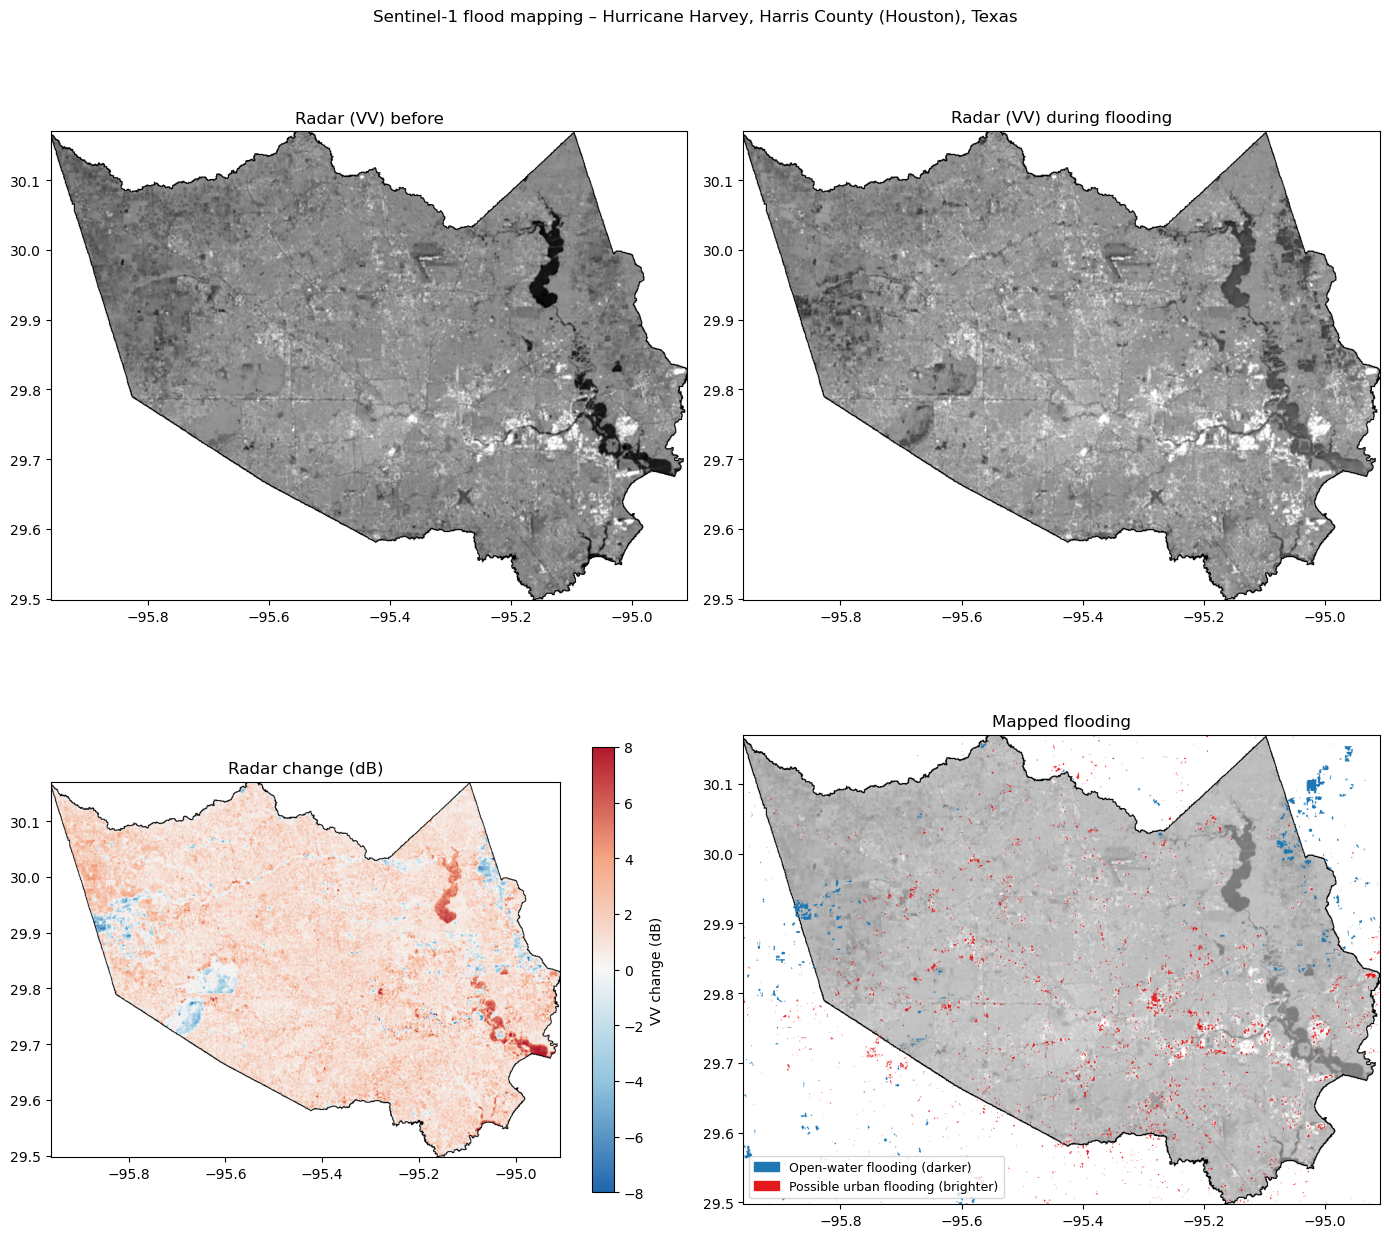

In [11]:
def thumb(key, vis_image, region, dims=1200):
    # Render a map once and save it; later runs load the saved image
    path = f"{MAP_DIR}/{key}.png"
    if os.path.exists(path) and not FORCE_RECOMPUTE:
        return np.array(Image.open(path))
    for size in (dims, 900, 600):
        try:
            url = vis_image.getThumbURL({"region": region, "dimensions": size, "crs": "EPSG:4326", "format": "png"})
            resp = requests.get(url, timeout=600); resp.raise_for_status()
            img = Image.open(io.BytesIO(resp.content)); img.save(path)
            return np.array(img)
        except Exception as e:
            print(f"  {key} at {size}px failed ({str(e)[:60]}), trying smaller")
    raise RuntimeError(f"Could not render {key}")

view = roi.bounds()
extent = [min(xs), max(xs), min(ys), max(ys)]
roi_line = ee.Image().byte().paint(ee.FeatureCollection([ee.Feature(roi)]), 1, 2).visualize(palette=["000000"])
grey_base = sar_before.clip(roi).visualize(min=-22, max=2, palette=["000000", "ffffff"], opacity=0.55).blend(roi_line)
white = ee.Image(1).visualize(palette=["ffffff"])
DIFF_PAL = ["2166ac", "92c5de", "f7f7f7", "f4a582", "b2182b"]
aspect = 1 / np.cos(np.deg2rad(29.8))

panels = [
    (thumb("sar_before", sar_before.clip(roi).visualize(min=-22, max=2).blend(roi_line), view), "Radar (VV) before", None),
    (thumb("sar_after", sar_after.clip(roi).visualize(min=-22, max=2).blend(roi_line), view), "Radar (VV) during flooding", None),
    (thumb("sar_change", white.blend(d_vv.clip(roi).visualize(min=-8, max=8, palette=DIFF_PAL)).blend(roi_line), view),
     "Radar change (dB)", "dB"),
    (thumb("flood_map", white.blend(grey_base).blend(open_flood.visualize(palette=["1f78b4"]))
                             .blend(urban_flood.visualize(palette=["e31a1c"])), view), "Mapped flooding", "classes"),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 13))
for ax, (arr, title, kind) in zip(axes.flat, panels):
    ax.imshow(arr, extent=extent); ax.set_title(title); ax.set_aspect(aspect)
    if kind == "dB":
        sm = plt.cm.ScalarMappable(cmap=LinearSegmentedColormap.from_list("d", ["#" + p for p in DIFF_PAL]), norm=Normalize(-8, 8))
        fig.colorbar(sm, ax=ax, label="VV change (dB)", shrink=0.7)
    if kind == "classes":
        ax.legend(handles=[mpatches.Patch(color="#1f78b4", label="Open-water flooding (darker)"),
                           mpatches.Patch(color="#e31a1c", label="Possible urban flooding (brighter)")],
                  loc="lower left", fontsize=9)
flood_arr = panels[3][0]       # kept for the comparison figure below
fig.suptitle(f"Sentinel-1 flood mapping – {EVENT_NAME}, {ROI_NAME}", y=0.995)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_radar_flood_map.png"); plt.show()

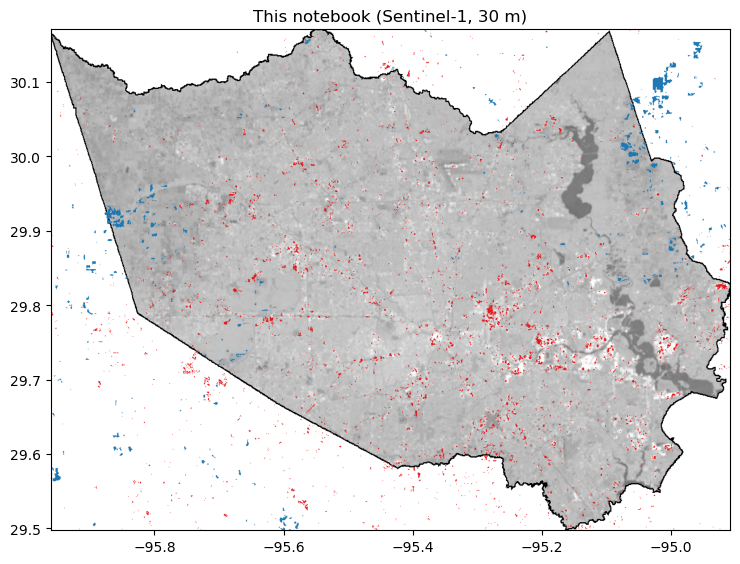

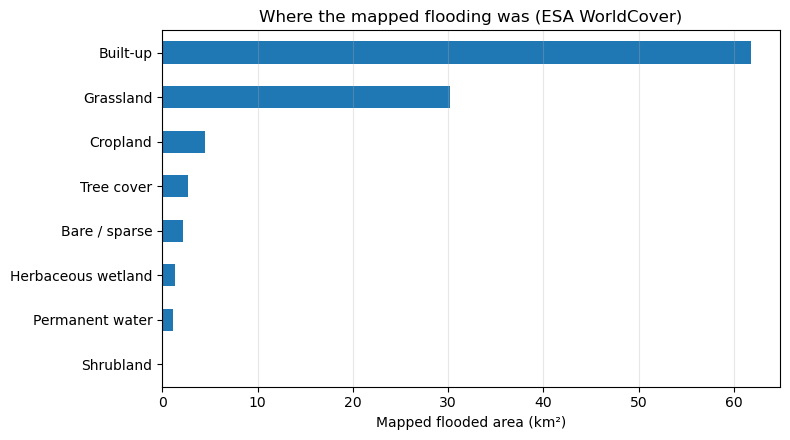

In [12]:
# My map next to the Global Flood Database extent
panels = [(flood_arr, "This notebook (Sentinel-1, 30 m)")]
if n_gfd:
    panels.append((thumb("gfd_map", white.blend(grey_base).blend(gfd_flood.visualize(palette=["6a3d9a"])), view),
                   "Global Flood Database (MODIS, 250 m)"))
fig, axes = plt.subplots(1, len(panels), figsize=(7.5 * len(panels), 7.5), squeeze=False)
for ax, (arr, title) in zip(axes[0], panels):
    ax.imshow(arr, extent=extent); ax.set_title(title); ax.set_aspect(aspect)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/02_comparison_global_flood_database.png"); plt.show()

# Flooded area by land cover
fig, ax = plt.subplots(figsize=(8, 4.5))
by_class.sort_values().plot.barh(ax=ax, color="#1f78b4")
ax.set(xlabel="Mapped flooded area (km²)", ylabel="", title="Where the mapped flooding was (ESA WorldCover)")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_flood_by_landcover.png"); plt.show()

## 8. Rainfall

GPM IMERG half-hourly precipitation, as in my original script. The `precipitation` band is a rate in mm/hour,
so each half-hourly image adds rate × 0.5 h to the daily total.

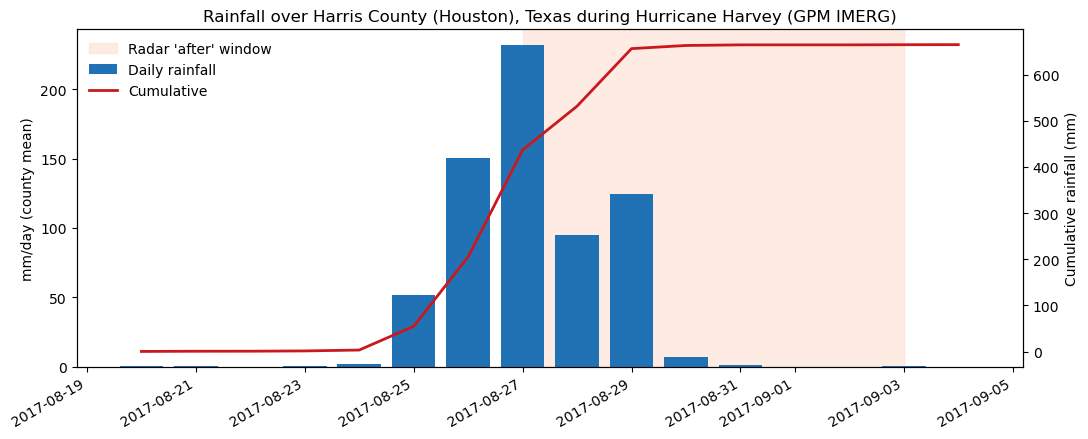

Total rainfall 2017-08-20 to 2017-09-05: 665 mm (county mean)


In [13]:
RAIN_CSV = f"{OUT_DIR}/daily_rain.csv"
if os.path.exists(RAIN_CSV) and not FORCE_RECOMPUTE:
    rain = pd.read_csv(RAIN_CSV, parse_dates=["date"]).set_index("date")["rain_mm"]
else:
    imerg = ee.ImageCollection("NASA/GPM_L3/IMERG_V07").select("precipitation")
    days = pd.date_range(*RAIN_WINDOW, freq="D", inclusive="left")
    def daily_rain(t):
        d0 = ee.Date(t)
        total = imerg.filterDate(d0, d0.advance(1, "day")).sum().multiply(0.5)
        return ee.Feature(None, {"date": d0.format("YYYY-MM-dd"),
                                 "rain_mm": total.reduceRegion(ee.Reducer.mean(), roi, 10000).get("precipitation")})
    rows = [f["properties"] for f in ee.FeatureCollection(
        ee.List([int(d.timestamp() * 1000) for d in days]).map(lambda t: daily_rain(t))).getInfo()["features"]]
    rain = pd.DataFrame(rows).assign(date=lambda d: pd.to_datetime(d["date"])).set_index("date")["rain_mm"].astype(float)
    rain.to_csv(RAIN_CSV)

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(rain.index, rain.values, color="#2171b5", label="Daily rainfall")
ax2 = ax1.twinx()
ax2.plot(rain.index, rain.cumsum(), color="#cb181d", lw=2, label="Cumulative")
ax1.axvspan(pd.Timestamp(SAR_AFTER[0]), pd.Timestamp(SAR_AFTER[1]), color="#fee0d2", alpha=0.6, zorder=0,
            label="Radar 'after' window")
ax1.set(ylabel="mm/day (county mean)", title=f"Rainfall over {ROI_NAME} during {EVENT_NAME} (GPM IMERG)")
ax2.set_ylabel("Cumulative rainfall (mm)")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left")
fig.autofmt_xdate()
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/04_rainfall.png"); plt.show()
print(f"Total rainfall {RAIN_WINDOW[0]} to {RAIN_WINDOW[1]}: {rain.sum():.0f} mm (county mean)")

## 9. Notes

- **Data:** Copernicus Sentinel-1 GRD; ESA WorldCover 2020 (v100); JRC Global Surface Water (Pekel et al. 2016);
  MERIT Hydro (Yamazaki et al. 2019); Global Flood Database (Tellman et al. 2021); WorldPop 2017;
  GPM IMERG Final V07 (Huffman et al.).
- **Reading the map:** blue (darker radar) is the most reliable flood signal. Red (brighter radar in built-up areas)
  is a *possible* urban flood signal: buildings brighten for other reasons too, so treat it as lower confidence.
- Radar only shows conditions at the moment the satellite passed. Harvey's flooding moved and changed over several days,
  so areas that drained before (or flooded after) the pass are missed.
- WorldCover is from 2020 and WorldPop from 2017; the population figure is an exposure estimate, not a count of people
  affected.
- Thresholds (`CHANGE_DB`, `WATER_DB`, `HAND_MAX`) are judgement calls; change them in Section 2 and compare.
- **Another storm or city:** change the county, the date windows and `EVENT_NAME`, and set `FORCE_RECOMPUTE = True`
  (or use new folder names in Section 2). The Global Flood Database ends in 2018, so for newer events the comparison
  is skipped automatically.